In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, sys, re, random, time
import importlib, traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
import tqdm

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
import faiss

import data_loaders
import miscellaneous
from rs_algorithm.models import TwoTowerRecommender, ThreeTowerRecommender, InteractionHistoryRepresentation
from rs_algorithm.models import AdaptiveRepresentation, SequenceRepresentation
from rs_algorithm.models.user_models.user_02_sim import DynamicPreferenceUserModel, dot_product_based_relavance_calculation
from dl_trainer import Trainer, split_collate, sequence_collate, create_sequence_collator
from data_loaders import CommitedDataset, commit_dataset, commit_dataset_jagged, JaggedCommittedDataset

In [3]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [4]:
try:
    ds_train_v2 = CommitedDataset('KuaiRecData_smaller', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [5]:
try:
    d_embed = 1024
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=1024, d_embed=d_embed, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=1024, d_embed=d_embed, id2idx=iid2idx)
    model = TwoTowerRecommender(user_model, item_model)
except:
    traceback.print_exc()

In [6]:
try:
    embed_trainer = Trainer(model=model, train_dataloader=DataLoader(ds_train_v2, batch_size=8192))
except:
    traceback.print_exc()

In [7]:
try:
    # embed_trainer.load_checkpoint('model_embedder_v4.1_mse_only.pt', save_backup=False)
    embed_trainer.load_checkpoint('model_id_trained_embedder_v2.pt', save_backup=False)
except:
    traceback.print_exc()

In [273]:
try:
    history_model = InteractionHistoryRepresentation(
        SequenceRepresentation('attention', d_embed, d_embed),
        SequenceRepresentation('attention', 1, 1),
    )
    for mod in (user_model, item_model):
        for par in mod.parameters():
            par.requires_grad = False
        mod.adaptor[2].p = 0.0
    recommender = ThreeTowerRecommender(d_embed, user_model, item_model, history_model)
except:
    traceback.print_exc()

In [128]:
try:
    with torch.no_grad():
        (uid, uft, pid, pif, nid, nif), truth = next(iter(ds_train_v2))
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))

        hid = torch.cat([nid, nid, nid], dim=0).unsqueeze(0)
        hft = torch.cat([nif, nif, nif], dim=0).unsqueeze(0)
        msk = torch.ones((1, 3))
        hcl = torch.ones((1, 3,))
        hcl[0, 1] = 0

        emb, *_ = recommender(uid, uft, hid, hft, hcl, msk)

        uem, ubs = user_model(uid, uft)
        pie, pib = item_model(pid, pif)
        nie, nib = item_model(nid, nif)

        print((uem * pie).mean(dim=1) + ubs + pib)
        print((uem * nie).mean(dim=1) + ubs + nib)
        print((uem * emb).mean(dim=1) + ubs)
except:
    traceback.print_exc()

Traceback (most recent call last):
  File "C:\Users\mcxiv\AppData\Local\Temp\ipykernel_18740\57849475.py", line 15, in <module>
    emb, *_ = recommender(uid, uft, hid, hft, hcl, msk)
              ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv_cpu\Lib\site-packages\torch\nn\modules\module.py", line 1779, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv_cpu\Lib\site-packages\torch\nn\modules\module.py", line 1790, in _call_impl
    return forward_call(*args, **kwargs)
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\rs_algorithm\models\recommenders.py", line 3, in forward
    import torch.nn.functional as F
                                  ^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv_cpu\Lib\site-packages\torch\nn\modules\module.py", line 1779, in _wrapped_call_impl
    return self._cal

In [129]:
class PretrainerDataset(Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.history_size = history_zise
        self.length = length

    def __len__(self):
        return self.length

    def __getitem__(self, idx: int):
        his = self.data_model.ratings['item_id'].sample(random.randint(5, self.history_size)).to_numpy()
        hfs = self.data_model.get_item_features(his)
        with torch.no_grad():
            hem, hbs = item_model(torch.tensor(his), torch.tensor(hfs))
            hem, hbs = hem.numpy(), hbs.numpy()
        hcs = np.random.randint(0, 2, (len(his),))

        eff_hem, eff_hbs = hem[hcs == 1], hbs[hcs == 1]
        if len(eff_hem) == 0: return self.__getitem__(idx)
        wei = np.linspace(0, 2 / len(eff_hem), len(eff_hem), dtype=np.float32)
        eff_hem, eff_hbs = (eff_hem * wei[:, None]).sum(0), (eff_hbs * wei).sum(0)
        with torch.no_grad():
            eff_hem = item_model.embedder[2](torch.tensor(eff_hem)).numpy()

        return (hem, hbs, hcs.astype(np.float32)), (eff_hem, eff_hbs)


try:
    pds = PretrainerDataset(data_model, 10, length=2048)
    for _, sample in zip(range(1), pds):
        print("sample", [y.shape for x in sample for y in x])
except:
    traceback.print_exc()

sample [(10, 1024), (10,), (10,), (1024,), ()]


In [130]:
try:
    abc = DataLoader(pds, batch_size=2, collate_fn=sequence_collate)
    for _, sample in zip(range(1), abc):
        print(sample[0][0].shape)
        print(sample[0][1].shape)
        print(sample[0][2].shape)
        print(sample[0][3].shape)
        print(sample[1][0].shape)
        print(sample[1][1].shape)
except:
    traceback.print_exc()

[(5, 1024), (5,), (5,)]
[torch.Size([2, 7, 1024]), torch.Size([2, 7]), torch.Size([2, 7])]
torch.Size([2, 7, 1024])
torch.Size([2, 7])
torch.Size([2, 7])
torch.Size([2, 7])
torch.Size([2, 1024])
torch.Size([2])


In [237]:
def pre_his_loss(preds, truth):
    hem, hbs = preds
    eff_hem, eff_hbs = truth
    # print(hem.dtype, hbs.dtype, eff_hem.dtype, eff_hbs.dtype)
    return F.mse_loss(hem, eff_hem) + F.mse_loss(hbs, eff_hbs.unsqueeze(-1))


def running_average(arr, window=10):
    return np.convolve(arr, np.ones(window), 'valid') / window


try:
    history_training_loss = locals().get('history_training_loss', None)
    history_trainer = Trainer(
        model=recommender.history_model,
        train_dataloader=DataLoader(pds, batch_size=512, collate_fn=sequence_collate),
        epochs=10,
        criterion=pre_his_loss,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.000001),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
    )
    history_training_loss = history_trainer.loss
    history_trainer.load_model("model_history_embeds_v2.pt")
except:
    traceback.print_exc()

In [13]:
try:
    history_trainer.epochs = 10
    # history_trainer.learning_rate(0.003)
except:
    traceback.print_exc()

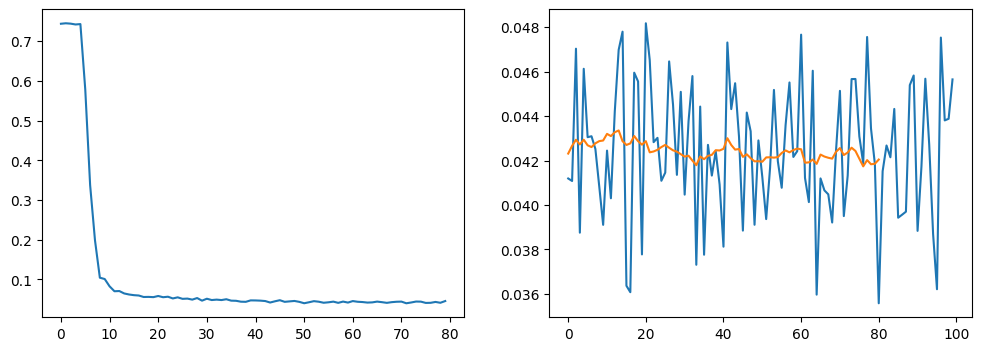

In [150]:
try:
    history_trainer.train()

    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(history_trainer.loss['train'])
    axs[1].plot(history_trainer.loss['batch.train'])
    axs[1].plot(running_average(history_trainer.loss['batch.train'], 20))
except:
    traceback.print_exc()

In [149]:
try:
    # history_trainer.loss['batch.train'] = history_trainer.loss['batch.train'][150:]
    print(len(history_trainer.loss['batch.train']))
except:
    traceback.print_exc()

100


In [151]:
try:
    history_trainer.save_model("history_embeds_v2")
except:
    traceback.print_exc()

In [167]:
try:
    print(data_model.ratings['item_id'].sample(1).values[0])
    print(data_model.ratings.iloc[0]['user_id'].astype(np.int64))
except:
    traceback.print_exc()

10358
1520


In [14]:
try:
    index = faiss.IndexFlatIP(d_embed)
    idxToIid = {}
    with torch.no_grad():
        for idx, iid in enumerate(data_model.ratings['item_id'].unique()):
            iem, *_ = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
            index.add(iem.numpy())
            idxToIid[idx] = iid
except:
    traceback.print_exc()

In [15]:
try:
    uid = random.randint(0, 1000)
    uft = data_model.get_user_features(uid)
    with torch.no_grad():
        uem, ubs = user_model(
            torch.tensor([uid], dtype=torch.int64),
            torch.tensor(uft[None, :], dtype=torch.float32))
        uem, ubs = uem.numpy(), ubs.numpy().squeeze()
        scores, indices = index.search(uem, 1)
        print(indices)
        iid = idxToIid[int(indices.squeeze())]
        ift = data_model.get_item_features(iid)
        iem, *_ = item_model(
            torch.tensor([iid], dtype=torch.int64),
            torch.tensor(data_model.get_item_features(iid)[None, :], dtype=torch.float32))
        iem = iem.numpy()
        print((uem * iem).sum())
except:
    traceback.print_exc()

[[2725]]
1.3494413


In [16]:
# def norm_press_preference(preference):
#     print("Hello", preference.shape)
#     with torch.no_grad():
#         return user_model.embedder[2](torch.tensor(preference)).numpy()


try:
    with torch.no_grad():
        uids = data_model.ratings['user_id'].unique()
        uem, _ = user_model(
            torch.tensor(uids, dtype=torch.int64),
            torch.tensor(data_model.get_user_features(uids), dtype=torch.float32))
        print(uem.shape)
    user_embed_mean = uem.mean(dim=1).mean().numpy()
    user_embed_std = uem.std(dim=1).mean().numpy()
    print("Mean", user_embed_mean, "Std", user_embed_std)


    def norm_press_preference(preference):
        preference = (preference - preference.mean()) / preference.std()
        return preference * user_embed_std + user_embed_mean

except:
    traceback.print_exc()

torch.Size([1411, 1024])
Mean -0.0016063001 Std 0.57845783


In [23]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def preference_function(pref, iem, ibs, ubs):
    # TODO: What would be a good way to convert it to probabilities?
    #  The raw preference calculated by the dot product ranges in -.6 to +.6 with an std of only 0.2
    #  For the time being I am using a simple hack
    print("pref", pref.min(), pref.max(), pref.std())
    print("iem", iem.min(), iem.max(), iem.std())
    print("SHAPE", pref.shape, iem.shape, (pref * iem).shape, ((pref * iem).sum()).shape)
    print("DOT", (pref * iem).min(), (pref * iem).max(), (pref * iem).std())
    dot = (pref * iem).sum()
    print("dotsum", dot.min(), dot.max(), dot.std())
    raw_relevance = (pref * iem).sum() + ubs + ibs.squeeze()
    print("raw_relevance", raw_relevance.std(), raw_relevance.min(), raw_relevance.max(), raw_relevance)
    return sigmoid(raw_relevance / 0.62 * 6)


class UserModelDataset_OLD(Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        self.ratings = self.ratings.sample(frac=1)
        self.history_size = history_zise
        self.length = length
        self.users = {}
        for uid in self.ratings['user_id'].unique():
            with torch.no_grad():
                uem, ubs = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(self.data_model.get_user_features(uid)[None, :], dtype=torch.float32))
                uem, ubs = uem.numpy(), ubs.numpy().squeeze()

            self.users[uid] = DynamicPreferenceUserModel(
                preference=uem,
                preference_volatility=0.01,
                relevance_calculator=lambda pref, iem, ibs, ubs=ubs: preference_function(pref, iem, ibs, ubs),
            )
        self.flip = True

    def __len__(self):
        # Actual length of ratings matrix is 998100
        # But data is infinite because of user model
        # So we can just iterate indefinitely
        # return len(self.ratings)
        return self.length

    def __getitem__(self, idx: int):
        idx = random.randint(0, len(self.ratings) - 1)
        user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
        user_feats = self.data_model.get_user_features(user_id)

        subset = data_model.ratings[data_model.ratings['user_id'] == user_id]

        user = self.users[user_id]
        user.reset()

        hist_id = []
        hist_feats = []
        hist_clk = []

        for iid in subset.sample(random.randint(5, self.history_size))['item_id']:
            ift = self.data_model.get_item_features(iid)
            hist_id.append(iid), hist_feats.append(ift)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                clk = np.int64(user.react(None, None, iem.numpy(), ibs.numpy()))
                # print(user._relevance)
                hist_clk.append(clk)
                # print(iem.std(), user.preference.std())

        if self.flip:
            # print("flip T", end=' ')
            subset = subset[subset['rating'] > 0.75]
        else:
            # print("flip F", end=' ')
            subset = subset[subset['rating'] <= 0.75]
        for iid in subset.sample(1)['item_id']:
            ift = self.data_model.get_item_features(iid)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                iem, ibs = iem.numpy(), ibs.numpy()
                clk = np.int64(user.react(None, None, iem, ibs))
                print("Rel", user._relevance)

        self.flip = not self.flip

        return ((
                    user_id,
                    user_feats,
                    np.array(hist_id, dtype=np.int64),
                    np.array(hist_feats, dtype=np.float32),
                    np.array(hist_clk, dtype=np.float32),
                ), (
                    iem.flatten(),
                    ibs,
                    clk,
                ))


class UserModelDataset(Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        self.ratings = self.ratings.sample(frac=1)
        self.history_size = history_zise
        self.length = length
        self.base_seed = random.randint(0, 1000000)

        self.users = {}

        with torch.no_grad():
            for uid in self.ratings['user_id'].unique():
                uem, ubs = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(self.data_model.get_user_features(uid)[None, :], dtype=torch.float32))
                uem, ubs = uem.numpy(), ubs.numpy().squeeze()

                self.users[int(uid)] = DynamicPreferenceUserModel(
                    preference=uem,
                    preference_bias=ubs,
                    preference_volatility=0.0,
                    relevance_calculator=dot_product_based_relavance_calculation,
                    preference_update_manager=norm_press_preference,
                )

    def __len__(self):
        return self.length

    def __getitem__(self, idx: int):
        random.seed(self.base_seed + idx)
        np.random.seed(self.base_seed + idx)
        # This line only exists since we want longer datasets, not matching up with the unique user counts
        # Otherwise, we could have used the idx on a separate unique user to rating map
        idx = random.randint(0, len(self.ratings) - 1)

        user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
        user_feats = self.data_model.get_user_features(user_id)
        user = self.users[int(user_id)]
        user.reset()

        hist_data = []

        # We need some positive samples, some negative... How do we proceed?

        for i in range(random.randint(5, self.history_size)):
            if random.random() < 0.8:  # Lol what!? 80%!?!?!
                iid = int(self.ratings['item_id'].iloc[np.random.randint(0, len(self.ratings))])
            else:
                iid = int(index.search(user.preference, 10)[1].flatten()[random.randint(0, 9)].squeeze())
                iid = idxToIid[iid]
            ift = self.data_model.get_item_features(iid)
            iem, ibs = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(ift[None, :], dtype=torch.float32))
            iem, ibs = iem.numpy(), ibs.numpy()

            # print("PEF", user.preference)
            # print("REL", (user.preference * iem).sum())

            # print("REL", user._get_relevance(None, None, iem, ibs))
            click = user.react(None, None, iem, ibs)
            # print("CLK", click)
            hist_data.append((iid, ift, click, iem, ibs))

        hist_id, hist_feats, hist_clk, _, _ = zip(*hist_data[:-1])

        return ((
                    user_id,
                    user_feats,
                    np.array(hist_id, dtype=np.int64),
                    np.array(hist_feats, dtype=np.float32),
                    np.array(hist_clk, dtype=np.float32),
                ), (
                    hist_data[-1][3].flatten(),
                    hist_data[-1][4],
                    np.float32(hist_data[-1][2]),
                ))


try:
    umd = UserModelDataset(data_model, 20, length=1024)
    for sample in umd:
        print(len(sample), len(sample[0]), len(sample[1]))
        print([x.shape for x in sample[0]])
        print([y.shape for y in sample[1]])
        break
except:
    traceback.print_exc()

2 5 3
[(), (1582,), (16,), (16, 429), (16,)]
[(1024,), (1,), ()]


In [20]:
try:
    sample = umd[11]
    print(sample[0][0]), print(sample[0][1][:6]), print(sample[0][2][:6]), print(sample[0][3][0, :6]), print(sample[0][4][:6])
    print(sample[1][0][:4]), print(sample[1][1]), print(sample[1][2])
except:
    traceback.print_exc()

6782
[ 0.          1.          0.          0.         -0.41807696  0.        ]
[ 794 5490 9553 7685 1429 8298]
[0. 0. 0. 0. 0. 0.]
[1. 1. 0. 0. 0. 0.]
[ 0.0929548  -0.01673301 -0.01197206 -0.17184345]
[-0.0939385]
1.0


### We want a balanced number of clock and non click predictions

Ideally `np.mean(clks) == 0.5`

In [17]:
try:
    pos = []
    neg = []
    clks = []
    # for _, ((uid, uft, hids, hfts, hclk), (iem, ibs, clk)) in zip(tqdm.tqdm(range(len(umd))), umd):
    for _, ((uid, uft, hids, hfts, hclk), (iem, ibs, clk)) in zip(tqdm.tqdm(range(1024)), umd):
        for cc in hclk.squeeze():
            if cc: pos.append(clk)
            else: neg.append(clk)
        clks.append(clk)
    print("Total POS in History", len(pos))
    print("Total NEG in History", len(neg))
    print("POS/NEG in History    (Expected 1.0) ", len(pos) / len(neg))
    print("Average Y Interaction (Expected 0.5) ", np.mean(clks))
except:
    traceback.print_exc()

100%|██████████| 1024/1024 [00:10<00:00, 95.86it/s]

Total POS in History 6279
Total NEG in History 5383
POS/NEG in History    (Expected 1.0)  1.1664499349804942
Average Y Interaction (Expected 0.5)  0.546875


### Checking if the data even has a bias towards positive predictions

Ideally `len(pos) / len(neg) == 1`

In [17]:
try:
    subset = data_model.ratings[data_model.ratings['user_id'] == 1520]
    uft = data_model.get_user_features(1520)
    with torch.no_grad():
        uem, ubs = user_model(
            torch.tensor([1520], dtype=torch.int64),
            torch.tensor(uft[None, :], dtype=torch.float32))
    pos, neg = [], []
    for iid in subset[subset['rating'] < 0.75]['item_id']:
        ift = data_model.get_item_features(iid)
        with torch.no_grad():
            iem, ibs = item_model(
                torch.tensor([iid], dtype=torch.int64),
                torch.tensor(ift[None, :], dtype=torch.float32))
            rel = float((iem * uem).sum() + ubs + ibs)
            rel = rel / 2 + 0.5
            if random.random() < rel: pos.append(1)
            else: neg.append(1)

    print(len(pos) / len(neg))
    # print(np.mean(pos), np.mean(neg))
except:
    traceback.print_exc()

0.6774193548387096


In [25]:
try:
    commit_dataset_jagged(umd, 'UserModelDataset', path=os.path.join('..', 'temp', 'commited_datasets'))
    umd_v2 = JaggedCommittedDataset('UserModelDataset', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

Pass 1/2: collecting lengths...


100%|██████████| 1024/1024 [00:10<00:00, 96.05it/s]


Pass 2/2: writing data...


100%|██████████| 1024/1024 [00:11<00:00, 91.44it/s] 


In [40]:
try:
    ids = []
    for sample in umd_v2:
        ids.append(sample[0][2].min())
        # print(sample[0][2].shape)
        # break
    print(np.min(ids))
except:
    traceback.print_exc()

103


In [253]:
def bce_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, ibs, clk = truth
    # print("uem, (ubs, hbs)", uem.shape, ubs.shape, hbs.shape)
    # print("iem, ibs, clk", iem.shape, ibs.shape, clk.shape)
    # print("iem stats:", iem.min().item(), iem.max().item(), iem.abs().mean().item())
    # print("uem stats:", uem.min().item(), uem.max().item(), uem.abs().mean().item())
    if ubs is None: ubs = 0
    # rel = torch.sigmoid(((uem * iem).sum(dim=1) + ubs.squeeze() + hbs.squeeze() + ibs.squeeze()) / 0.62 * 6)
    logit = (uem * iem).sum(dim=1) + ubs.squeeze() + hbs.squeeze() + ibs.squeeze()
    # print(f"logit mean={logit.mean():.3f}, std={logit.std():.3f}")
    # print("logit", logit.shape)
    return F.binary_cross_entropy_with_logits(logit, clk.squeeze())


def mse_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, ibs, clk = truth
    if ubs is None: ubs = 0
    # TODO: Rfere to the same comment made in user model regarding probability conversion to understand `/ 0.62 * 6`
    rel = torch.sigmoid(((uem * iem).sum(dim=1) + ubs + ibs) / 0.62 * 6)
    # print(rel)
    return F.mse_loss(rel, clk)


def collate_fn(list_of_stuff):
    uid, uft, hid, hft, hcl = tuple(zip(*([x[0] for x in list_of_stuff])))
    uid = torch.tensor(uid)
    uft = torch.tensor(uft)
    max_seq = max(len(x) for x in hid)
    mask = torch.tensor([[i < len(x) for i in range(max_seq)] for x in hid], dtype=torch.float32)
    hid = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hid])
    hft = torch.tensor([np.pad(x, [(0, max_seq - len(x)), (0, 0)]) for x in hft])
    hcl = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hcl])
    iem, ibs, clk = tuple(zip(*([x[1] for x in list_of_stuff])))
    iem = torch.tensor(iem)
    ibs = torch.tensor(ibs).flatten()
    clk = torch.tensor(clk).float()
    return (uid, uft, hid, hft, hcl, mask), (iem, ibs, clk)

In [198]:
loss = None

In [274]:
try:
    trainer = Trainer(
        model=recommender,
        # train_dataloader=DataLoader(umd_v2, batch_size=16, collate_fn=collate_fn),
        train_dataloader=DataLoader(umd_v2, batch_size=16, collate_fn=create_sequence_collator(
            (False, False, True, True, True)
        )),
        # train_dataloader=DataLoader(umd_v2, batch_size=16, collate_fn=sequence_collate),
        epochs=5,
        criterion=bce_loss,
        # criterion=mse_loss,
        # optimizer=lambda x: torch.optim.Adam(x, lr=0.001),
        optimizer=lambda x: torch.optim.SGD(x, lr=0.003),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=loss,
    )
    loss = trainer.loss
except:
    traceback.print_exc()

In [216]:
# try:
#     # trainer.load_checkpoint('checkpoint_RegressionBasedBPEModel_001_20260402_171557_0.7496953347667319.pt', save_backup=False)
#     trainer.load_checkpoint(save_backup=False)
# except:
#     traceback.print_exc()

In [268]:
try:
    trainer.epochs = 1
    # trainer.optimizer = torch.optim.AdamW([
    #     {'params': recommender.history_model.parameters(), 'lr': 0.001},
    #     {'params': recommender.alpha.parameters(), 'lr': 0.00001},
    # ], lr=0.0)
    # print(recommender.history_model)
except:
    traceback.print_exc()

In [275]:
try:
    trainer.train()
    # TODO: Try weight based model for history embeds instead of RNN
    # 2 epochs, battery, 61 sec
    # 2 epochs, charge, same
except:
    traceback.print_exc()

user_model.embedder.0.weight: None
user_model.embedder.2.weight: None
user_model.embedder.2.bias: None
user_model.adaptor.0.weight: None
user_model.adaptor.0.bias: None
user_model.adaptor.3.weight: None
user_model.adaptor.3.bias: None
user_model.adaptor.4.weight: None
user_model.adaptor.4.bias: None
user_model.alpha.0.weight: None
user_model.alpha.0.bias: None
user_model.bias.weight: None
item_model.embedder.0.weight: None
item_model.embedder.2.weight: None
item_model.embedder.2.bias: None
item_model.adaptor.0.weight: None
item_model.adaptor.0.bias: None
item_model.adaptor.3.weight: None
item_model.adaptor.3.bias: None
item_model.adaptor.4.weight: None
item_model.adaptor.4.bias: None
item_model.alpha.0.weight: None
item_model.alpha.0.bias: None
item_model.bias.weight: None
history_model.hem_embed.model.encoder.self_attn.in_proj_weight: 5.41e+01
history_model.hem_embed.model.encoder.self_attn.in_proj_bias: 5.74e+00
history_model.hem_embed.model.encoder.self_attn.out_proj.weight: 6.75e+0

Traceback (most recent call last):
  File "C:\Users\mcxiv\AppData\Local\Temp\ipykernel_18740\711715578.py", line 2, in <module>
    trainer.train()
    ~~~~~~~~~~~~~^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\dl_trainer\trainer.py", line 149, in train
    for param_group in self.optimizer.param_groups:
        ^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\dl_trainer\trainer.py", line 21, in _train_step
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv_cpu\Lib\site-packages\torch\_tensor.py", line 631, in backward
    torch.autograd.backward(
    ~~~~~~~~~~~~~~~~~~~~~~~^
        self, gradient, retain_graph, create_graph, inputs=inputs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv_cpu\Lib\site-packages\torch\autograd\__init__.py", line 381, in backward
    _engine_run_backward(
    ~~~~~~~~~~~~~~~~~~~~^
        tensors,
        ^^^^^^

In [233]:
try:
    for name, param in recommender.named_parameters():
        print(name, param.requires_grad)
except:
    traceback.print_exc()

user_model.embedder.0.weight: None
user_model.embedder.2.weight: None
user_model.embedder.2.bias: None
user_model.adaptor.0.weight: None
user_model.adaptor.0.bias: None
user_model.adaptor.3.weight: None
user_model.adaptor.3.bias: None
user_model.adaptor.4.weight: None
user_model.adaptor.4.bias: None
user_model.alpha.0.weight: None
user_model.alpha.0.bias: None
user_model.bias.weight: None
item_model.embedder.0.weight: None
item_model.embedder.2.weight: None
item_model.embedder.2.bias: None
item_model.adaptor.0.weight: None
item_model.adaptor.0.bias: None
item_model.adaptor.3.weight: None
item_model.adaptor.3.bias: None
item_model.adaptor.4.weight: None
item_model.adaptor.4.bias: None
item_model.alpha.0.weight: None
item_model.alpha.0.bias: None
item_model.bias.weight: None
history_model.hem_embed.model.encoder.self_attn.in_proj_weight: None
history_model.hem_embed.model.encoder.self_attn.in_proj_bias: None
history_model.hem_embed.model.encoder.self_attn.out_proj.weight: None
history_mo

dict_keys(['train', 'val', 'epoch.train', 'batch.train'])
46


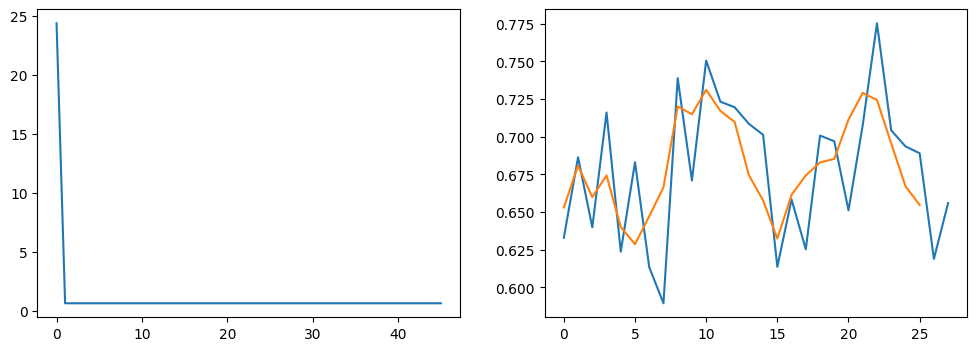

In [267]:
try:
    def running_average(arr, window=3):
        return np.convolve(arr, np.ones(window), 'valid') / window


    print(trainer.loss.keys())
    print(len(trainer.loss['epoch.train']))
    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(trainer.loss['train'])
    axs[1].plot(trainer.loss['batch.train'])
    axs[1].plot(running_average(trainer.loss['batch.train']))
except:
    traceback.print_exc()

In [264]:
try:
    print(len(trainer.loss['batch.train']))
    # trainer.loss['batch.train'] = trainer.loss['batch.train'][301:]
except:
    traceback.print_exc()

28


In [191]:
try:
    with torch.no_grad():
        (uid, uft, hid, hft, hcl, msk), (iem, ibs, clk) = next(iter(DataLoader(umd_v2, collate_fn=collate_fn)))

        uem, ubs = user_model(uid, uft)
        print("Without History", (uem * iem).sum() + ubs + ibs)

        pref = torch.tensor(umd.users[uid.item()].preference)
        print("Actual Preference", (pref * iem).sum() + ubs + ibs)
        print("Click", clk)

        pref = torch.tensor(umd.users[uid.item()]._state_vector['preference'])
        print("Original Preference", (pref * iem).sum() + ubs + ibs)

        alpha = recommender.alpha(uem)
        print('history weight', 1 - alpha)

        uem2, (ubs2, hbs) = recommender(uid, uft, hid, hft, hcl, msk)
        print("With History", (uem2 * iem).sum() + ubs2 + ibs + hbs)

except:
    traceback.print_exc()

Without History tensor([[0.1002]])
Actual Preference tensor([[0.1023]])
Click tensor([[1.]])
Original Preference tensor([[0.1002]])
history weight tensor([[0.5480]], grad_fn=<RsubBackward1>)
With History tensor([[9.2439]], grad_fn=<AddBackward0>)


In [196]:
try:
    # print(uem2.sum().backward(retain_graph=True))
    print(list(history_model.parameters())[0].grad)
    # print(len(trainer.loss['batch.train']))
    # trainer.loss['batch.train'] = trainer.loss['batch.train'][5:]
except:
    traceback.print_exc()

tensor([[ 4.9341e-13,  1.2419e-12, -1.6405e-12,  ..., -2.0743e-13,
          1.0383e-12,  1.5189e-12],
        [-7.4167e-13,  1.4457e-12, -6.8558e-13,  ..., -5.3903e-13,
         -3.9808e-13,  1.6038e-12],
        [ 6.9785e-13, -5.4107e-13, -1.1364e-12,  ..., -2.0999e-12,
          2.1749e-12,  1.5372e-12],
        ...,
        [ 5.2793e-10, -4.3848e-10,  1.7664e-10,  ..., -4.7190e-10,
          9.5793e-10,  8.3558e-10],
        [-6.1459e-10,  5.3446e-10, -1.7237e-10,  ...,  5.9194e-10,
         -1.1252e-09, -9.4877e-10],
        [ 3.5366e-10, -2.5509e-10,  4.0333e-11,  ..., -3.4047e-10,
          6.8172e-10,  6.1709e-10]])


In [227]:
try:
    trainer.save_model("recommender_v3")
    trainer.save_loss("recommender_v3")
except:
    traceback.print_exc()